# Exercise 1: Selecting and evaluating a polynomial model

Consider the model
$$
y_i = f(x_i) + \epsilon_i,\qquad
f(x) = \sin\bigl(2\pi(x + 0.1)\bigr),
$$
where $x_i$ is uniform on $[0,1]$ and the independently and identically
distributed (i.i.d.) errors satisfy
$\epsilon_i \stackrel{\mathrm{iid}}{\sim} N(0, 0.5^2)$.
For this exercise, assume that we don't know the true model and are instead
approximating $f$ with a polynomial of degree $D$, i.e.,
$$
y_i = \beta_0 + \beta_1 x_i + \beta_2 x_i^2 + \cdots + \beta_D x_i^D + u_i,
$$
where $u_i$ is the residual not explained by the polynomial.

In this exercise, we use cross-validation (CV) to select a polynomial degree,
refit the selected model, and evaluate its predictions on independent observations.
We first compute the validation scores for each degree, then reproduce the same
selection using higher-level scikit-learn functions.

## Setup

The true function, sample generator, and plotting functions are provided in the
following cells.
We use 100 training observations for all model selection and fitting. We generate
an independent test sample only after selecting and fitting the models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng

In [2]:
def fcn(x):
    """
    Evaluate the true sine relationship.

    Parameters
    ----------
    x : array-like
        Input values

    Returns
    -------
    array
        True function values
    """
    return np.sin(2 * np.pi * (x + 0.1))

In [3]:
def generate_sample(n_obs, sigma, rng=None):
    """
    Generate a sample with uniform inputs and normally distributed errors.

    Parameters
    ----------
    n_obs : int
        Number of observations
    sigma : float
        Standard deviation of the errors
    rng : generator, optional
        Random number generator used for the draws

    Returns
    -------
    X : array
        Feature matrix with one column
    y : array
        Observed outcomes
    """
    if rng is None:
        rng = default_rng(seed=1234)

    # Draw uniform inputs
    x = rng.uniform(size=n_obs)
    # Draw normally distributed errors
    epsilon = rng.normal(scale=sigma, size=n_obs)
    # Add the errors to the true function values
    y = fcn(x) + epsilon
    # Reshape x to a feature matrix with one column
    X = x[:, None]
    return X, y

In [4]:
def plot_sample(X, y):
    """
    Plot the training observations and true function.

    Parameters
    ----------
    X : array
        Feature matrix with one column
    y : array
        Observed outcomes
    """
    x_grid = np.linspace(0, 1, 301)
    _fig, ax = plt.subplots(figsize=(4.5, 3), layout='constrained')
    ax.scatter(X[:, 0], y, s=20, c='none', ec='steelblue', lw=0.75, label='Training')
    ax.plot(x_grid, fcn(x_grid), c='black', lw=1, label='True function')
    ax.set(xlabel='$x$', ylabel='$y$', xlim=(0, 1), ylim=(-2.5, 2.5))
    ax.legend()
    return ax

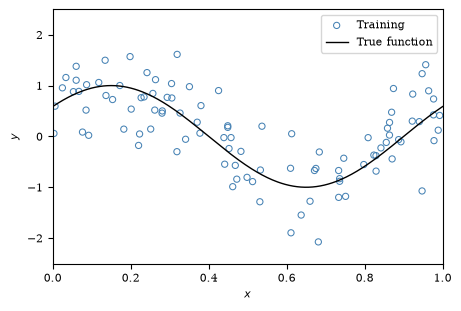

In [5]:
# Number of observations
n_obs = 100

# Standard deviation of the errors
sigma = 0.5

# Generate the sample
X, y = generate_sample(n_obs, sigma)

# Plot the sample
_ = plot_sample(X, y)

***
## Part 1 — Constructing the pipeline

As a first step, build a
[`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
called `pipe` with these named steps:

1. `input_scale`: use
   [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
   to center and scale the input.
2. `poly`: use
   [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
   with `degree=1` and `include_bias=False`.
3. `scale`: standardize the expanded features with another `StandardScaler`.
4. `lr`: fit
   [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
   with `fit_intercept=True`.

Explain why the scalers must be inside the pipeline when we use cross-validation.

Test that the pipeline works by fitting it to the sample generated above.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# TODO: Build pipe with the specified steps

# TODO: Test pipeline by fitting it on X and y.

### Solution

We scale the input before taking powers to improve numerical stability, then
scale the expanded columns. Both scalers are fitted on each fold's training
observations. Fitting them before CV would let the held-out observations influence
the transformations.

Excluding the polynomial bias column avoids a redundant constant column when the
regression includes an intercept.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pipe = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=1, include_bias=False)),
        ('scale', StandardScaler()),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

# Fit the pipeline to the sample
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('input_scale', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[0.51]


<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Computing MSEs for one degree

In this part, you are asked to implement a function that returns the average
training and validation MSEs across CV folds for a given polynomial degree.

1. Define a CV splitter using
    [`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
    with ten shuffled folds and a fixed seed of 1234.
2. Complete the function `compute_average_mse()` below. Use
    [`cross_validate()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
    to compute the training and validation mean squared errors (MSEs) for each fold.
    The function takes an estimator, the training data, and a CV splitter, and
    returns the mean training and validation MSEs across folds.

    *Hint*: Pass `scoring='neg_mean_squared_error'` and `return_train_score=True`
    as arguments to `cross_validate()`.

    *Hint*: Don't forget to negate the scores before returning the MSEs.

Test your function implementation with the pipeline from Part 1, the CV splitter
from (1), and the training data generated earlier.

In [8]:
from sklearn.model_selection import cross_validate


def compute_average_mse(estimator, X, y, cv):
    """
    Compute mean training and validation MSEs across CV folds.

    Parameters
    ----------
    estimator : estimator
        Regression model or pipeline
    X : array-like
        Explanatory variables
    y : array-like
        Response variable
    cv : splitter
        Cross-validation splitter

    Returns
    -------
    mse_train : float
        Mean training MSE across folds
    mse_validate : float
        Mean validation MSE across folds
    """
    # TODO: Run cross_validate() with training scores and negative MSE scoring.

    # TODO: Negate and average the training and validation scores.

    # TODO: Return the two mean MSEs.


# TODO: Define a CV splitter with ten shuffled folds and a random state of 1234.

# TODO: Test compute_average_mse() with the pipeline, sample, and CV splitter.

### Solution

We first define the CV splitter using the `KFold` class:

In [9]:
from sklearn.model_selection import KFold

# Define the CV splitter
cv_splitter = KFold(n_splits=10, shuffle=True, random_state=1234)

Next, we use `cross_validate()` in our implementation of `compute_average_mse()`
to fit a fresh copy of the pipeline on each fold's training observations.
We average the returned scores across folds and negate them.

In [10]:
from sklearn.model_selection import cross_validate


def compute_average_mse(estimator, X, y, cv):
    """
    Compute mean training and validation MSEs across CV folds.

    Parameters
    ----------
    estimator : estimator
        Regression model or pipeline
    X : array-like
        Explanatory variables
    y : array-like
        Response variable
    cv : splitter
        Cross-validation splitter

    Returns
    -------
    mse_train : float
        Mean training MSE across folds
    mse_validate : float
        Mean validation MSE across folds
    """
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring='neg_mean_squared_error',
        return_train_score=True,
    )

    # Negate scores to get MSEs and average across folds
    mse_train = -scores['train_score'].mean()
    mse_validate = -scores['test_score'].mean()
    return mse_train, mse_validate

We can test the function with the pipeline and CV splitter defined above:

In [11]:
# Test with the pipeline and CV splitter defined above
mse_train, mse_validate = compute_average_mse(pipe, X, y, cv_splitter)

print(f'Training MSE: {mse_train:.4f}')
print(f'Validation MSE: {mse_validate:.4f}')

Training MSE: 0.5246
Validation MSE: 0.5482


<span style="display: none;">SolutionEnd</span>

***
## Part 3 — Plotting the validation curve

We now want to use the function `compute_average_mse()` implemented in Part 2 to
compute the mean training and validation MSEs for polynomial degrees 1 through 15.
We are therefore "manually" computing the validation curve.
Recall that the validation curve plots the training and validation scores as a
function of a hyperparameter, in this case the polynomial degree.

1. Loop over degrees 1 through 15. For each degree, you can either recreate the
    pipeline with the new degree or use `pipe.set_params()` to change
    `poly__degree` on an existing pipeline (see code template below).
    
    Call your `compute_average_mse()` function with the same CV splitter defined
    in Part 2 to compute the mean training and validation MSEs for each degree
    and store these.
2. Find and report the degree with the smallest mean validation MSE.
3. Use the supplied `plot_validation_curve()` function to plot the training and
    validation MSEs as a function of the polynomial degree.

In [12]:
def plot_validation_curve(degrees, mse_train, mse_validation, best_degree):
    """
    Plot mean training and validation MSEs against polynomial degree.

    Parameters
    ----------
    degrees : array-like
        Candidate polynomial degrees
    mse_train : array-like
        Mean training MSE for each degree
    mse_validation : array-like
        Mean validation MSE for each degree
    best_degree : int
        Degree with the smallest mean validation MSE
    """
    _fig, ax = plt.subplots(figsize=(5.5, 3), layout='constrained')
    ax.plot(degrees, mse_train, c='black', marker='x', ms=4, label='Training')
    ax.plot(
        degrees, mse_validation, c='steelblue', marker='o', ms=4, label='Validation'
    )
    ax.axvline(best_degree, ls=':', lw=0.75, c='black')
    ax.set(xlabel='Polynomial degree', ylabel='Mean CV MSE', xticks=degrees)
    ax.legend()

In [13]:
# Degrees of the polynomial features to consider
degrees = np.arange(1, 16)

for degree in degrees:
    # Update the degree of the polynomial features in the pipeline
    pipe.set_params(poly__degree=degree)

    # TODO: Compute the mean training and validation MSEs for the current degree

    # TODO: Store the mean training and validation MSEs for each degree

# TODO: Find and report the degree with the smallest mean validation MSE

# TODO: Plot the validation curve using the supplied `plot_validation_curve()` function

### Solution

In [14]:
# Degrees of the polynomial features to consider
degrees = np.arange(1, 16)

# Lists to store the mean training and validation MSEs for each degree
mse_train_mean = []
mse_validate_mean = []

for d in degrees:
    # Update the degree of the polynomial features in the pipeline
    pipe.set_params(poly__degree=d)
    # Compute the mean training and validation MSEs for the current degree
    mse_train_d, mse_validate_d = compute_average_mse(pipe, X, y, cv_splitter)

    # Store the mean training and validation MSEs for current degree
    mse_train_mean.append(mse_train_d)
    mse_validate_mean.append(mse_validate_d)

# Find index of the degree with the smallest mean validation MSE
imin = np.argmin(mse_validate_mean)
# Recover the degree with the smallest mean validation MSE
dmin = degrees[imin]
print(f'Degree with minimum validation MSE: {dmin}')
print(f'Minimum CV MSE: {mse_validate_mean[imin]:.3f}')

Degree with minimum validation MSE: 5
Minimum CV MSE: 0.271


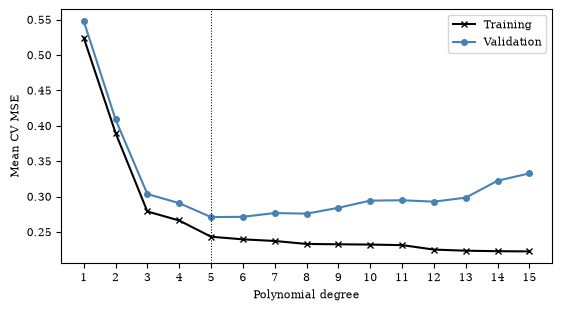

In [15]:
# Plot validation curve and indicate the optimal degree
plot_validation_curve(degrees, mse_train_mean, mse_validate_mean, dmin)

Degree 5 minimizes the mean validation MSE at about 0.271. Training MSE falls
as the polynomial becomes more flexible, while validation MSE eventually rises.
The validation curve need not be a smooth U: its values fluctuate across
neighboring degrees.

<span style="display: none;">SolutionEnd</span>

***
## Part 4 — Using `validation_curve()`

Instead of computing the validation curve manually, we can use the convenience function
[`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html).

1. Repeat the degree comparison using `validation_curve()`.
    Use the same pipeline, candidate degrees, CV splitter, and negative-MSE scorer.

    What do the rows and columns of the returned arrays represent?
2. Average each returned score array across folds and negate the scores.
    Check that the resulting training and validation MSEs agree with Part 3 using
    [`np.allclose()`](https://numpy.org/doc/stable/reference/generated/numpy.allclose.html).

In [16]:
from sklearn.model_selection import validation_curve

# TODO: Call validation_curve() with param_name='poly__degree'.

# TODO: Average across folds, negate the scores, and compare with Part 3.

### Solution

`validation_curve()` handles the loop over degrees. Both returned arrays have
shape `(15, 10)`: rows correspond to degrees and columns to folds.

In [17]:
# Compute the validation curve by varying the polynomial degree poly__degree
train_scores, validate_scores = validation_curve(
    pipe,
    X,
    y,
    param_name='poly__degree',
    param_range=degrees,
    cv=cv_splitter,
    scoring='neg_mean_squared_error',
)

# Compute average scores across folds (folds are in columns, hence axis=1)
mse_train_curve = -train_scores.mean(axis=1)
mse_validate_curve = -validate_scores.mean(axis=1)

We can use `np.allclose()` to check that the mean training and validation MSEs
agree with those computed in Part 3.

In [18]:
print('Training MSEs are close:', np.allclose(mse_train_mean, mse_train_curve))
print('Validation MSEs are close:', np.allclose(mse_validate_mean, mse_validate_curve))

Training MSEs are close: True
Validation MSEs are close: True


For comparison, we can also draw the same validation curve using
[`ValidationCurveDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ValidationCurveDisplay.html).
We construct the display from the scores already computed, so CV is not repeated.
The argument `negate_score=True` displays positive MSEs.

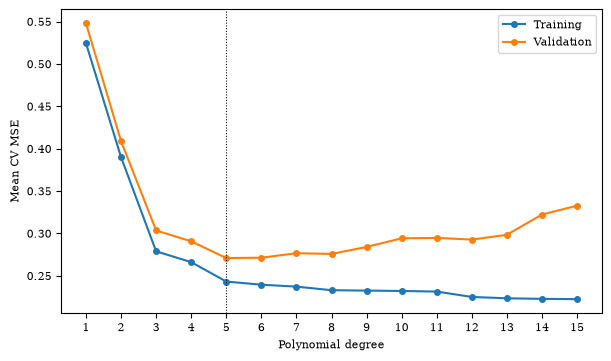

In [19]:
from sklearn.model_selection import ValidationCurveDisplay

display = ValidationCurveDisplay(
    param_name='poly__degree',
    param_range=degrees,
    train_scores=train_scores,
    test_scores=validate_scores,
    score_name='MSE',
)
fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
display.plot(
    ax=ax,
    negate_score=True,
    std_display_style=None,
    line_kw={'marker': 'o', 'markersize': 4},
)
ax.axvline(dmin, ls=':', lw=0.75, c='black')
ax.set(xlabel='Polynomial degree', ylabel='Mean CV MSE', xticks=degrees)
_ = ax.legend(['Training', 'Validation'])

<span style="display: none;">SolutionEnd</span>

***
## Part 5 — Selecting and refitting automatically

Next, we want to select the polynomial degree and refit the model automatically
using
[`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
instead of computing the validation curve manually.

1. Use `GridSearchCV` to select among the same degrees, using the same pipeline,
    folds, and scorer.

    *Hint:* Set `refit=True` to automatically refit the best model on the full training data.

2. Print the selected degree using the `best_params_` attribute and its mean validation MSE from
    the `best_score_` attribute of the `GridSearchCV` object. 
    Remember to negate the score to obtain the MSE.

    Compare the printed values with the results from Part 3.

In [20]:
from sklearn.model_selection import GridSearchCV

# TODO: Create grid_search with the same degree grid, splitter, and scorer.

# TODO: Fit the search on X and y, then print the selected degree and CV MSE.

### Solution

The parameter name `poly__degree` combines the pipeline step name and its
parameter, separated by two underscores. With `refit=True`, the search fits the
selected pipeline on all 100 training observations after comparing the CV scores.

In [21]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {'poly__degree': degrees}

# Create grid_search with the same degree grid, splitter, and scorer.
grid_search = GridSearchCV(
    pipe,
    param_grid,  # parameters to search over
    cv=cv_splitter,  # cross-validation splitter
    scoring='neg_mean_squared_error',  # scoring metric
    refit=True,  # refit the best model on the whole dataset
    n_jobs=4,  # number of jobs to run in parallel
)

# Run the grid search on the data
grid_search.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': array([ 1, 2..., 13, 14, 15])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [22]:
# Extract the selected degree from the grid search results
selected_degree = grid_search.best_params_['poly__degree']

print(f'Selected degree: {selected_degree}')
print(f'Minimum CV MSE: {-grid_search.best_score_:.3f}')

Selected degree: 5
Minimum CV MSE: 0.271


The search again selects degree 5 with a minimum CV MSE of about 0.271.
`best_estimator_` contains the refitted pipeline, ready to predict new observations.
The copies fitted during CV used only nine of the ten folds each.

<span style="display: none;">SolutionEnd</span>

***
## Part 6 — Comparing fitted models

You are now asked to visually compare the fitted models with degree 1, the
CV-selected degree, and degree 15.

1. Fit the comparison models with degrees 1 and 15 on all training observations, and use
    `GridSearchCV`'s `best_estimator_` attribute for the selected best model.

    *Hint:* Instead of defining new pipelines, you can use
    [`clone()`](https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html)
    to create unfitted copies of the pipeline for degrees 1 and 15,
    and then adjust their `poly__degree` parameter using
    `set_params(poly__degree=...)`.
2. Use the supplied function below to plot a fitted model together with the
    sample and true function. Call it once for each model to create three
    separate plots.
3. Explain how the plots relate to the validation curve.

In [23]:
def plot_fitted_model(X, y, model, title):
    """
    Plot one fitted model with the sample and true function.

    Parameters
    ----------
    X : array
        Training feature matrix with one column
    y : array
        Training outcomes
    model : estimator
        Fitted regression model or pipeline
    title : str
        Plot title
    """
    ax = plot_sample(X, y)
    x_grid = np.linspace(0, 1, 301)
    y_hat = model.predict(x_grid[:, None])
    ax.plot(x_grid, y_hat, c='darkorange', lw=1.25, label='Fitted polynomial')
    ax.set_title(title)
    ax.legend()

In [24]:
from sklearn.base import clone

# Fit degree-1 copy of pipe.
model_d1 = clone(pipe).set_params(poly__degree=1).fit(X, y)

# TODO: Fit degree-15 copy of pipe.

# TODO: Save best model from grid_search.best_estimator_ as best_model

# TODO: Call plot_fitted_model() for each of the three models.

### Solution

We use the refitted `best_estimator_` for the selected degree and fit separate
copies for the comparison models. All three plots use the same axis limits.

In [25]:
from sklearn.base import clone

# Clone and fit the degree 1 model
model_d1 = clone(pipe).set_params(poly__degree=1).fit(X, y)

# Clone and fit the degree 15 model
model_d15 = clone(pipe).set_params(poly__degree=15).fit(X, y)

# Extract the best model from the grid search
best_model = grid_search.best_estimator_

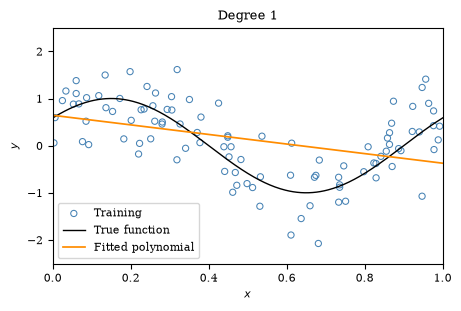

In [26]:
plot_fitted_model(X, y, model_d1, 'Degree 1')

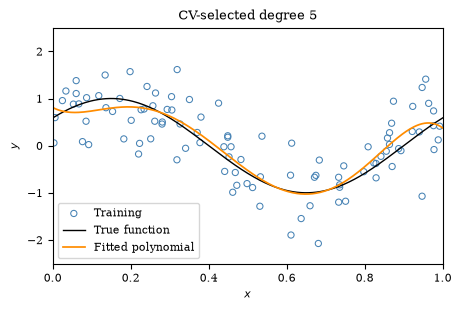

In [27]:
title = f'CV-selected degree {selected_degree}'
plot_fitted_model(X, y, best_model, title)

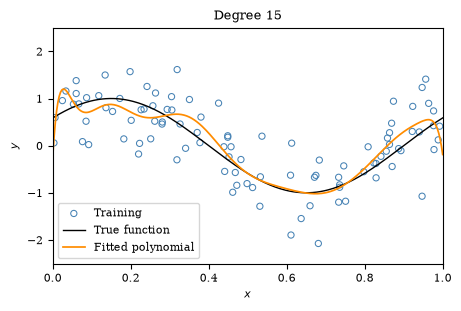

In [28]:
plot_fitted_model(X, y, model_d15, 'Degree 15')

The linear (degree 1) model misses the curved relationship. The selected model
follows the true function more closely. Degree 15 fits the training observations
more closely but has a higher CV error. Its fitted curve is somewhat more
variable; the validation scores help us assess differences that may be hard to
judge visually.

<span style="display: none;">SolutionEnd</span>

***
## Part 7 — Independent evaluation

We used cross-validation to choose the polynomial degree and then fitted the
selected model on all 100 training observations. We now evaluate predictions
using a new test sample. These observations were not used to choose the degree
or fit any of the models.

Because these data are simulated, we can generate a new test sample instead of
setting aside some of the original observations.

1. Use `generate_sample()` to generate 10,000 independent test observations with
    `default_rng(5678)`, the same true function, and the same noise level.
2. Use
    [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
    to report training and test MSE for the three models fitted in Part 6.

Explain:

1. Which model has the lowest training MSE? Which has the lowest test MSE?
2. Compare degree 15 with the CV-selected degree. Does the lower training MSE
    translate into better predictions on the test sample? Explain the difference.

In [29]:
import pandas as pd
from sklearn.metrics import mean_squared_error

# TODO: Generate the test sample X_test, y_test

# TODO: Compute and report each model's training and test MSE.

### Solution

We generate a new test sample and evaluate the three fitted models without
fitting them again.

In [30]:
# Initialize an RNG with a different seed to get new test sample
rng_test = default_rng(5678)

# Generate the test sample
X_test, y_test = generate_sample(10_000, sigma, rng_test)

In [31]:
import pandas as pd
from sklearn.metrics import mean_squared_error

# Dictionary of models to evaluate
models = {1: model_d1, selected_degree: best_model, 15: model_d15}

rows = []

for degree, model in models.items():
    # Compute each model's training and test MSE
    train_mse = mean_squared_error(y, model.predict(X))
    test_mse = mean_squared_error(y_test, model.predict(X_test))

    rows.append(
        {'Model': f'Degree {degree}', 'Training MSE': train_mse, 'Test MSE': test_mse}
    )

# Build a DataFrame to report the training and test MSEs for each model
df_errors = pd.DataFrame(rows)
df_errors

,Model,Training MSE,Test MSE
0,Degree 1,0.525792,0.614275
1,Degree 5,0.244521,0.273138
2,Degree 15,0.226415,0.294391


Degree 15 has the lowest training MSE (about 0.226), while the CV-selected
degree 5 has the lowest test MSE (about 0.273).

Compared with degree 5, degree 15 reduces training MSE from about 0.245 to 0.226
but increases test MSE from about 0.273 to 0.294. Its additional flexibility
lets it fit some of the random noise in the training sample. That noise does
not help predict new observations, so its test MSE is higher.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 2: Categorical features

In this exercise, we practice fitting models that include categorical features in the
regressor matrix $\mathbf{X}$ using the Ames housing dataset. There are several
categorical variables in this data that come in two different kinds:

1.  [Nominal categorical variables](https://en.wikipedia.org/wiki/Nominal_category)
    capture qualitative categories. For numerical purposes, we often encode these as
    integer values, but any particular integer representation is arbitrary. It is a
    serious mistake to include such integer-valued categorical variables as *continuous*
    features in a model.

    In the Ames housing data, the `Neighborhood` column is one such nominal categorical
    variable (stored as a string containing the neighborhood name).

2.  [Ordinal categorical variables](https://en.wikipedia.org/wiki/Ordinal_data)
    represent data that have a natural ordering, but the distance between any two values
    can be arbitrary.
    
    For example, in the Ames housing data the `OverallQuality` variable is an ordinal
    categorical variable on a scale of 1–10. While a value of 2 is clearly better than a
    value of 1, it is up to interpretation how much better.

    Such variables can be included as categorical *dummy variables* in a model, not
    imposing any particular interpretation on the distance between two values.
    Alternatively, such variables can be included as *continuous* variables, which
    imposes how the distance is interpreted. For example, including an ordinal
    categorical variable as a linear term in a model imposes that moving from 1 to 2 has
    the same effect on the outcome variable as moving from 2 to 3.

***
## Part 1 — Creating the estimation sample

We load the Ames data the same way as we did in the lectures:

In [32]:
import pandas as pd

# Use local data/ folder
DATA_PATH = '../../data'

filename = f'{DATA_PATH}/ames_houses.csv'
df = pd.read_csv(filename, sep=',')

First, perform the following data preprocessing steps:

1.   Drop all observations that have any missing values for `SalePrice`,
     `OverallQuality`, or `Neighborhood`.
2.   Tabulate how many neighborhoods have fewer than 40 observations, and drop
     observations from these neighborhoods from the dataset.

### Solution

In [33]:
# Keep only obs with non-missing data for relevant variables
variables = ['SalePrice', 'OverallQuality', 'Neighborhood']
df = df.dropna(subset=variables)

In [34]:
# Compile list of neighborhoods with fewer than 40 observations
nobs = df['Neighborhood'].value_counts().sort_values()

# Select neighborhoods with fewer than minimum observations
MIN_OBS = 40
few_nobs = nobs.loc[nobs < MIN_OBS]

print(
    f'Number of neighborhoods with fewer than {MIN_OBS} observations: {len(few_nobs)}'
)
# Print these neighborhoods
few_nobs

Number of neighborhoods with fewer than 40 observations: 9


Neighborhood
Landmrk     1
GrnHill     2
Greens      8
Blueste    10
NPkVill    23
Veenker    24
Blmngtn    28
BrDale     30
MeadowV    37
Name: count, dtype: int64

In [35]:
# Keep only neighborhoods with minimum number of observations
nobs = df.groupby('Neighborhood')['Neighborhood'].transform('count')
df = df[nobs >= MIN_OBS]

<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Train-test split

Split the data into a training and a test sample, assigning 40% of observations to
the test sample, and report the number of observations in each set.

Stratify your split by `Neighborhood` to preserve approximately the same
neighborhood proportions in both samples. Use the `stratify` argument of
[`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
and specify a random seed of 1234.

You can pass the whole `DataFrame` to `train_test_split()` instead of individual
`X` and `y` values. The function then returns two DataFrames, one containing the
training data and one containing the test data.

### Solution

In [36]:
from sklearn.model_selection import train_test_split

# Fraction of sample to use for testing
test_size = 0.4

# Split sample into training and test samples using the whole DataFrame
df_train, df_test = train_test_split(
    df, test_size=test_size, stratify=df['Neighborhood'], random_state=1234
)

print(f'Number of observations in training sample: {len(df_train):5,d}')
print(f'Number of observations in test sample:     {len(df_test):5,d}')

Number of observations in training sample: 1,660
Number of observations in test sample:     1,107


<span style="display: none;">SolutionEnd</span>

***
## Part 3 — Exploratory data analysis

Use only `df_train` for the following exploratory analysis so that test outcomes
do not guide model development:

1. Compute the correlations of `SalePrice` with the other numerical variables.
   Which explanatory variable has the highest correlation?
2. Create a bar chart of `OverallQuality`, showing the number of observations
   for each quality level 1–10.

   *Hint:* Create a `Series` with the number of observations per quality level
   and plot it using
   [`Series.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html).

3. Create a box plot showing `SalePrice` by `OverallQuality`.

   *Hint:* You can use
   [`DataFrame.plot.box()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.box.html)
   for this.

4. Create a box plot showing `SalePrice` by `Neighborhood`.

### Solution

We can compute the pairwise correlations using the
[`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
method. This returns the whole (symmetric) correlation matrix, but since we are
interested only in the correlations with `SalePrice`, we select only that row.

In [37]:
# Compute training-sample correlations with the explanatory variables
df_train.corr(numeric_only=True).loc['SalePrice'].drop('SalePrice').sort_values(
    ascending=False
)

OverallQuality          0.796639
LivingArea              0.715426
BasementArea            0.637367
YearBuilt               0.563902
Bathrooms               0.543826
YearRemodeled           0.532033
Fireplaces              0.471543
FinishedBasementArea    0.393978
LotArea                 0.241002
HasGarage               0.221328
Bedrooms                0.144113
MonthSold               0.047169
YearSold               -0.026633
OverallCondition       -0.121497
Name: SalePrice, dtype: float64

As the table shows, `OverallQuality` is the explanatory variable that has the highest
correlation with `SalePrice`.

Next, we create a bar chart depicting the number of observations by overall quality. We
can do this by grouping by `OverallQuality` and counting the number of elements with
[`size()`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.size.html)
and then using the pandas plotting routines to create a bar chart.

<Axes: xlabel='Overall quality', ylabel='Number of observations'>

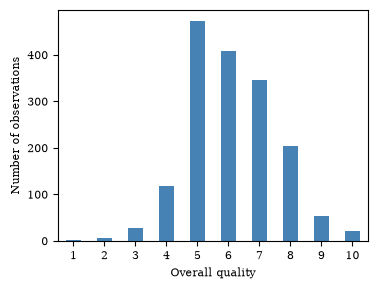

In [38]:
# Count training observations at each quality level
df_train.groupby('OverallQuality').size().reindex(range(1, 11), fill_value=0).plot.bar(
    rot=0, color='steelblue', xlabel='Overall quality', ylabel='Number of observations'
)

We use the
[`DataFrame.plot.box()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.box.html)
method to create a box plot of the sale price by overall quality.

SalePrice    Axes(0.125,0.11;0.775x0.77)
dtype: object

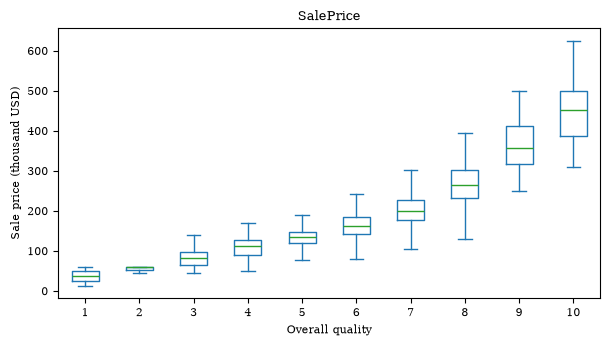

In [39]:
df_train.plot.box(
    by='OverallQuality',
    column='SalePrice',
    showfliers=False,
    figsize=(7, 3.5),
    ylabel='Sale price (thousand USD)',
    xlabel='Overall quality',
)

As you can see, there is a clear increasing relationship between sale price and overall quality.

The same approach can be used to create the box plot by neighborhood:

SalePrice    Axes(0.125,0.11;0.775x0.77)
dtype: object

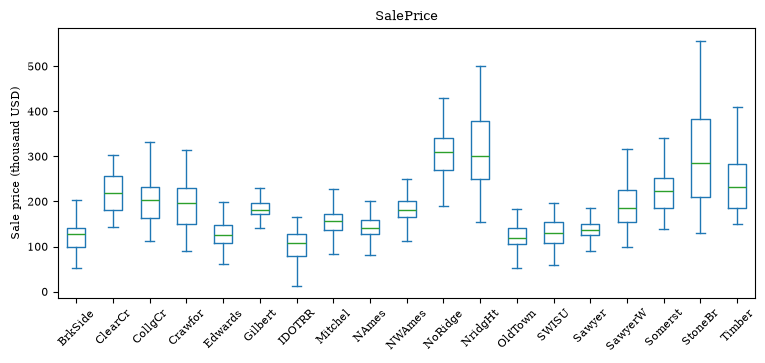

In [40]:
df_train.plot.box(
    by='Neighborhood',
    column='SalePrice',
    showfliers=False,
    figsize=(9, 3.5),
    ylabel='Sale price (thousand USD)',
    xlabel='',
    rot=45,
)

<span style="display: none;">SolutionEnd</span>

***
## Part 4 — Predicting price by neighborhood

Create an estimator pipeline to fit the model
$$
SalePrice_{ij} = \mu_j + \epsilon_{ij}
$$
where $i$ indexes observations and $j$ indexes neighborhoods. That is, the sale price
for a house $i$ in neighborhood $j$ is predicted to be the average sale price $\mu_j$ in
that neighborhood.

In order to estimate this model, you'll have to convert the categorical string variable
`Neighborhood` to a set of 0/1 dummy variables. This can be achieved using the
[`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
as a step in a pipeline.

Fit the model on the training data, and report the RMSE both on the training and the
test sample.

This is a predetermined baseline. Use training data and CV scores to choose
between the quality models in the remaining parts.

### Solution

We first extract the target and features from the training and test DataFrames. Note
that scikit-learn expects a feature *matrix*, so we should extract the features as a
list of columns even if there is only a single feature.

In [41]:
features = ['Neighborhood']
target = 'SalePrice'

# Extract features and target variable
X_train, y_train = df_train[features], df_train[target]
X_test, y_test = df_test[features], df_test[target]

We can now build an estimation pipeline that uses
[`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
as a data preprocessing step. This step converts the categorical variables into a
matrix of zeros and ones, where each column corresponds to one neighborhood and
contains 1 if the observation is located in that neighborhood, and 0 otherwise.

Note that we need to either drop the first category (`drop='first'`) if we want to fit
the model with an intercept, or specify `fit_intercept=False`. Otherwise, the
regressor matrix $\mathbf{X}$ will be collinear.

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

# Drop first dummy column, estimate model with intercept
pipe_dummies = make_pipeline(
    OneHotEncoder(drop='first', sparse_output=False),
    LinearRegression(fit_intercept=True),
)

Alternatively and equivalently, we can specify the estimation pipeline as follows:

In [43]:
# Don't drop first dummy column, don't estimate model with additional intercept
pipe_dummies = make_pipeline(
    OneHotEncoder(drop=None, sparse_output=False), LinearRegression(fit_intercept=False)
)

In [44]:
# Fit the model
pipe_dummies.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequ

With the fitted model, we can inspect the estimated coefficients:

In [45]:
# Match each estimated neighborhood mean to its category label
neighborhoods = pipe_dummies.named_steps['onehotencoder'].categories_[0]
coefficients = pipe_dummies.named_steps['linearregression'].coef_
pd.Series(coefficients, index=neighborhoods, name='Mean price (thousand USD)')

BrkSide    124.243077
ClearCr    216.938462
CollgCr    204.387500
Crawfor    201.872581
Edwards    134.881034
Gilbert    189.113131
IDOTRR     104.092857
Mitchel    162.120588
NAmes      145.115789
NWAmes     187.277215
NoRidge    332.820930
NridgHt    319.100000
OldTown    126.475524
SWISU      130.137931
Sawyer     136.491209
SawyerW    190.429333
Somerst    224.846789
StoneBr    308.777419
Timber     244.165116
Name: Mean price (thousand USD), dtype: float64

There are 19 estimated coefficients, one for each neighborhood in the data.
The encoder's `categories_` attribute gives the labels in the order of the dummy
columns. Each labeled estimate is the neighborhood's mean training sale price,
measured in thousands of USD.

We use the fitted model to predict prices and compute RMSE.

In [46]:
from sklearn.metrics import root_mean_squared_error

y_train_hat = pipe_dummies.predict(X_train)
y_test_hat = pipe_dummies.predict(X_test)

rmse_train = root_mean_squared_error(y_train, y_train_hat)
rmse_test = root_mean_squared_error(y_test, y_test_hat)

print(f'Training RMSE (thousand USD): {rmse_train:.5f}')
print(f'Test RMSE (thousand USD): {rmse_test:.5f}')

Training RMSE (thousand USD): 53.58493
Test RMSE (thousand USD): 52.82692


<span style="display: none;">SolutionEnd</span>

***
## Part 5 — Polynomial in overall quality

Fit the model
$$
SalePrice_i = \beta_0 + \beta_1 OverallQuality_i
+ \beta_2 OverallQuality_i^2 + \dots + \beta_d OverallQuality_i^d + \epsilon_i
$$
for polynomial degrees $d=1,2,\dots,9$. This treats quality as a numeric predictor
and imposes a smooth relationship across its ordered levels. In the next part,
we compare this with a separate mean for each quality category.

Use the template below and
[`cross_validate()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
to compute mean training and validation RMSEs. Include `StandardScaler` both
before and after `PolynomialFeatures(degree=d, include_bias=False)`, followed by
`LinearRegression(fit_intercept=True)`. Keep the scalers inside the pipeline.

Use `scoring='neg_root_mean_squared_error'` and `return_train_score=True`.
The arrays under `train_score` and `test_score` contain negative RMSEs for each
fold; `test_score` refers to the CV validation folds.

Plot the mean training and validation RMSEs and report the degree with the
smallest mean validation RMSE. Reuse `cv_quality` for the dummy-model comparison.
The training observations are already in random order after the train-test split,
so we keep that order when assigning the five folds.

In [47]:
import numpy as np
from sklearn.model_selection import KFold

features = ['OverallQuality']
target = 'SalePrice'
X_train, y_train = df_train[features], df_train[target]
X_test, y_test = df_test[features], df_test[target]

degrees = np.arange(1, 10)
cv_quality = KFold(n_splits=5)
rmse_train_mean = []
rmse_validate_mean = []

for d in degrees:
    # TODO: Create the scaling + polynomial features + regression pipeline.

    # TODO: Compute training and validation scores using cross_validate().
    # scores = cross_validate(
    #     estimator=...,
    #     X=X_train, y=y_train,
    #     scoring=...,
    #     cv=cv_quality,
    #     return_train_score=True,
    #     n_jobs=4
    # )

    # TODO: Negate and average the scores across folds.
    # rmse_train_mean.append(np.mean(-scores['train_score']))
    # rmse_validate_mean.append(np.mean(-scores['test_score']))

    pass

### Solution

The template selects `OverallQuality` as a one-column feature matrix.
We scale the input before creating powers and scale the expanded columns before
regression, using the same pipeline structure as in Exercise 1.

We create a pipeline for each degree and run CV with the shared splitter.
The chosen scorer returns negative RMSE, so we negate and average the scores
across folds. All RMSEs are measured in thousands of USD.

In [48]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Polynomial degrees to consider
degrees = np.arange(1, 10)

rmse_train_mean = []
rmse_validate_mean = []

for d in degrees:
    # Create polynomial features + linear regression pipeline
    pipe_lr = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression(fit_intercept=True),
    )

    # Run cross-validation. Function returns a dictionary with scores
    scores = cross_validate(
        estimator=pipe_lr,  # Estimator to use
        X=X_train,
        y=y_train,  # Data to fit
        scoring='neg_root_mean_squared_error',  # Scoring metric
        cv=cv_quality,  # Shared five-fold splitter
        return_train_score=True,  # Also return training scores
        n_jobs=4,  # Fit up to four folds in parallel
    )

    # Compute average RMSE over all CV splits
    rmse_train_mean.append(np.mean(-scores['train_score']))
    rmse_validate_mean.append(np.mean(-scores['test_score']))

# Convert to NumPy arrays
rmse_train_mean = np.array(rmse_train_mean)
rmse_validate_mean = np.array(rmse_validate_mean)

Using this data, we can determine the optimal polynomial degree as the one that
minimizes the mean validation RMSE across folds.

In [49]:
# Find degree that minimizes RMSE
imin = np.argmin(rmse_validate_mean)
dmin = degrees[imin]

print(f'Polynomial degree with min. RMSE: {dmin}')

Polynomial degree with min. RMSE: 3


Finally, the following code creates the validation curve.

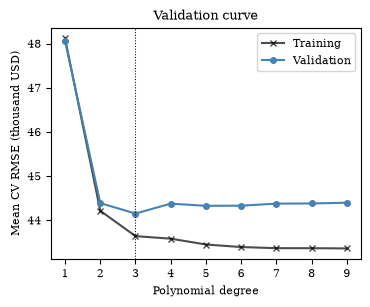

In [50]:
import matplotlib.pyplot as plt

# Plot validation curve
plt.plot(
    degrees, rmse_train_mean, c='black', marker='x', ms=4, alpha=0.7, label='Training'
)
plt.plot(
    degrees, rmse_validate_mean, c='steelblue', marker='o', ms=4, label='Validation'
)
plt.xlabel('Polynomial degree')
plt.ylabel('Mean CV RMSE (thousand USD)')
plt.xticks(degrees)
plt.axvline(dmin, ls=':', lw=0.75, c='black')
plt.title('Validation curve')
plt.legend()

<span style="display: none;">SolutionEnd</span>

***
## Part 6 — Quality dummies

Compare the polynomial models with a separate mean for each quality category:
$$
SalePrice_{ij} = \mu_j + \epsilon_{ij},
$$
where $j$ indexes the quality levels 1–10. A house with quality $j$ is predicted
to have the average training sale price of houses with that quality.

Create a pipeline with `OneHotEncoder` and `LinearRegression`, then evaluate it
using the same observations, `cv_quality` splitter, and RMSE scorer as in Part 5.
The dummy model has no polynomial degree to tune, but CV lets us compare its
predictive performance with the polynomial models.

Recreate the validation curve and add horizontal lines for the dummy model's mean
training and validation RMSEs. Compare its scores with those of degree 9. Why
might these agree when all ten quality levels occur in every training fold?

Choose between the best polynomial model and the dummy model using their mean
validation RMSEs, before inspecting their test predictions.

In [51]:
# TODO: Create pipeline with dummy variables + estimation

# TODO: Run cross-validation
# scores = cross_validate(
#     estimator=...,
#     X=X_train, y=y_train,
#     scoring=...,
#     cv=cv_quality,
#     return_train_score=True,
#     n_jobs=4
# )

# TODO: Compute average RMSE over all CV splits
# rmse_train_dummies_mean = np.mean(-scores['train_score'])
# rmse_validate_dummies_mean = np.mean(-scores['test_score'])

### Solution

In [52]:
from sklearn.preprocessing import OneHotEncoder

# Create pipeline with dummy variables + linear regression
pipe_dummies = make_pipeline(
    OneHotEncoder(drop='first'), LinearRegression(fit_intercept=True)
)

# Run cross-validation
scores = cross_validate(
    estimator=pipe_dummies,
    X=X_train,
    y=y_train,
    scoring='neg_root_mean_squared_error',
    cv=cv_quality,
    return_train_score=True,
    n_jobs=4,
)

# Compute average RMSE over all CV splits
rmse_train_dummies_mean = np.mean(-scores['train_score'])
rmse_validate_dummies_mean = np.mean(-scores['test_score'])

print(f'Average RMSE on train sample: {rmse_train_dummies_mean:.5f}')
print(f'Average RMSE on validation sample: {rmse_validate_dummies_mean:.5f}')

print(
    'Degree-9 training RMSE agrees:',
    np.isclose(rmse_train_mean[-1], rmse_train_dummies_mean),
)
print(
    'Degree-9 validation RMSE agrees:',
    np.isclose(rmse_validate_mean[-1], rmse_validate_dummies_mean),
)

if rmse_validate_mean[imin] < rmse_validate_dummies_mean:
    preferred_model = f'Polynomial degree {dmin}'
else:
    preferred_model = 'Quality dummies'
print(f'Preferred model using CV: {preferred_model}')

Average RMSE on train sample: 43.35949
Average RMSE on validation sample: 44.39483
Degree-9 training RMSE agrees: True
Degree-9 validation RMSE agrees: True
Preferred model using CV: Polynomial degree 3


We use the same plotting code as above, and add the horizontal lines for the dummy variable model on top.

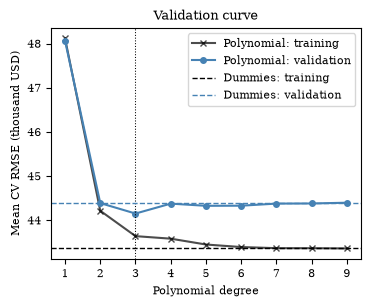

In [53]:
# Plot validation curve
plt.plot(
    degrees,
    rmse_train_mean,
    c='black',
    marker='x',
    ms=4,
    alpha=0.7,
    label='Polynomial: training',
)
plt.plot(
    degrees,
    rmse_validate_mean,
    c='steelblue',
    marker='o',
    ms=4,
    label='Polynomial: validation',
)
plt.xlabel('Polynomial degree')
plt.ylabel('Mean CV RMSE (thousand USD)')
plt.xticks(degrees)
plt.axvline(dmin, ls=':', lw=0.75, c='black')

# Add horizontal lines for RMSE from dummy variable regressions
plt.axhline(
    rmse_train_dummies_mean, ls='--', lw=1.0, c='black', label='Dummies: training'
)
plt.axhline(
    rmse_validate_dummies_mean,
    ls='--',
    lw=1.0,
    c='steelblue',
    label='Dummies: validation',
)
plt.title('Validation curve')
plt.legend()

The dummy model estimates a separate mean for each quality level, so it can fit
the training data at least as closely as the polynomial models. With ten distinct
quality levels, a degree-9 polynomial with an intercept can reproduce any set of
ten fitted category means. All ten levels occur in each training fold here, so
the degree-9 and dummy models have the same scores up to numerical precision:
training RMSE is about 43.35949 and validation RMSE is about 44.39483.

Greater flexibility does not guarantee better predictions. Separate category
means can be estimated imprecisely when a quality level has few observations.
A low-degree polynomial restricts how predicted prices vary across levels.

CV favors degree 3, with mean validation RMSE about 44.14963, over the dummy
model's 44.39483. We choose the cubic before evaluating the two models on the
test sample.
<span style="display: none;">SolutionEnd</span>

***
## Part 7 — Comparing test predictions

Refit the selected polynomial and the dummy model on the whole training sample
and compute their test RMSEs. Report the results for both predetermined models.

Does the test ranking agree with the CV ranking from Part 6? How large is the
difference in test RMSE? Discuss what this comparison tells us without revising
the model choice using the test results.

### Solution

In [54]:
# Re-estimate polynomial model on the whole training sample
pipe_poly_best = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=dmin, include_bias=False),
    StandardScaler(),
    LinearRegression(fit_intercept=True),
).fit(X_train, y_train)

# Re-estimate dummies model on the whole training sample
pipe_dummies.fit(X_train, y_train)

# Predict response variable on test sample
y_test_poly_hat = pipe_poly_best.predict(X_test)
y_test_dummies_hat = pipe_dummies.predict(X_test)

# Compute RMSE on test sample
rmse_test_poly = root_mean_squared_error(y_test, y_test_poly_hat)
rmse_test_dummies = root_mean_squared_error(y_test, y_test_dummies_hat)

print(f'RMSE on test sample (polynomial): {rmse_test_poly:.5f}')
print(f'RMSE on test sample (dummies): {rmse_test_dummies:.5f}')

RMSE on test sample (polynomial): 42.93533
RMSE on test sample (dummies): 42.82456


Test RMSE is about 42.93533 for the cubic and 42.82456 for the dummy model,
measured in thousands of USD. The dummy model has the smaller test RMSE on this
split, reversing the CV ranking. The difference is only about 0.111 thousand USD,
or $111, roughly 0.26% of the cubic's test RMSE.

The two samples give slightly different rankings. This small test difference
does not establish that the dummy representation is generally better. Our model
choice used CV; the test results report its performance after selection.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 3: Predicting loan interest rates with PCR

In this exercise, we build a model to predict a loan's interest rate from loan
and borrower characteristics. We use principal component regression (PCR) to
combine related predictors, and cross-validation to decide whether polynomial
features and dimension reduction improve predictions.

We use data on 10,000 funded loans from OpenIntro's
[Lending Club dataset](https://openintrostat.github.io/openintro/reference/loans_full_schema.html),
stored in the file `lending_club.csv`.
The loans were issued in the first quarter of 2018.

Our target is `interest_rate`, the annual interest rate in percent.
We use the following eleven predictors. Counts and loan term enter as numeric
variables. Homeownership and income verification enter as indicators.

| Predictor | Description |
| --- | --- |
| `loan_amount` | Loan principal in US dollars |
| `term` | Loan term, either 36 or 60 months |
| `annual_income` | Applicant's annual income in US dollars |
| `debt_to_income` | Monthly debt payments as a percentage of monthly income |
| `homeowner` | 1 for mortgage or outright ownership; 0 for renting |
| `income_verified` | 1 if the source or amount of income was verified; 0 otherwise |
| `credit_history_years` | Issue year minus earliest credit-line year |
| `inquiries_last_12m` | Number of credit inquiries in the preceding 12 months |
| `open_credit_lines` | Number of open credit lines |
| `total_credit_limit` | Existing credit limit excluding mortgages, in US dollars |
| `credit_utilization` | Existing credit balance / limit, excluding mortgages |

Credit utilization is a fraction: 0.5 means 50%. Both the balance and the limit
exclude mortgages. These variables describe existing credit accounts across
lenders, including accounts outside Lending Club. We interpret them as the
applicant's credit position at application, before the loan in that row is issued.

## Setup

We load the data and define the predictor list below. The setup keeps individual
applications so that income and debt-to-income describe one applicant's finances.
It removes observations missing the target or a selected predictor.
The resulting DataFrame, `df_data`, contains 8,503 loans.

All model development will use the training sample; the test sample is reserved
for Part 5.

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Path to CSV in data/ folder
DATA_PATH = '../../data/lending-club'
df_raw = pd.read_csv(f'{DATA_PATH}/lending_club.csv')

# Select features and target variable for regression
features = [
    'loan_amount',
    'term',
    'annual_income',
    'debt_to_income',
    'homeowner',
    'income_verified',
    'credit_history_years',
    'inquiries_last_12m',
    'open_credit_lines',
    'total_credit_limit',
    'credit_utilization',
]
target = 'interest_rate'

# Keep individual applications (drop joint applications)
df_individual = df_raw.query("application_type == 'individual'")
# Keep only observations with non-missing values for the selected features and target
df_data = df_individual.dropna(subset=[*features, target])

print(f'Loans in the teaching sample: {len(df_raw):,}')
print(f'Usable observations: {len(df_data):,}')

Loans in the teaching sample: 10,000
Usable observations: 8,503


***
## Part 1 — Splitting and inspecting the sample

We first set aside a test sample to evaluate predictions on unseen loans.
We then inspect the training predictors' scales and correlations to see why
standardization and PCA may be useful.

1. Use the prepared `df_data` sample and
   [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
   to reserve 30% for testing, with `random_state=1234`. Name the resulting
   objects `X_train`, `X_test`, `y_train`, and `y_test`.
   Report the number of training and test observations.
2. Using only the training sample, report each predictor's mean, standard
   deviation, minimum, and maximum.

   Why would PCA on the unscaled predictors be sensitive to their units?

3. Create the correlation heatmap by calling `plot_correlations(X_train)` using
   the provided function below. It computes the correlation matrix and reads the
   predictor names from `X_train` automatically.

In [56]:
def plot_correlations(X):
    """
    Plot an annotated heatmap of predictor correlations.

    Parameters
    ----------
    X : dataframe
        Training predictors with named columns
    """
    df_corr = X.corr()

    fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
    heatmap = ax.imshow(df_corr, cmap='RdBu_r', vmin=-1, vmax=1)

    # Label the rows and columns with the predictor names
    positions = range(len(df_corr.columns))
    ax.set_xticks(positions, labels=df_corr.columns, rotation=45, ha='right')
    ax.set_yticks(positions, labels=df_corr.columns)

    # Display each correlation inside its cell
    for i in positions:
        for j in positions:
            correlation = df_corr.iloc[i, j]
            text_color = 'white' if abs(correlation) > 0.5 else 'black'
            ax.text(
                j,
                i,
                f'{correlation:.2f}',
                ha='center',
                va='center',
                c=text_color,
                fontsize=8,
            )

    fig.colorbar(heatmap, ax=ax, label='Correlation', shrink=0.5)
    ax.set_title('Training predictor correlations')
    plt.show()

In [57]:
from sklearn.model_selection import train_test_split

# TODO: Split df_data into training and test sets and report their sizes.

# TODO: Inspect training predictor descriptive statistics

# TODO: Create correlation heatmap using plot_correlations(X_train).

### Solution

The setup provides 8,503 complete individual applications. We allocate 5,952 to
training and 2,551 to testing.

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_data[features], df_data[target], test_size=0.3, random_state=1234
)

print(f'Training observations: {len(y_train):,}')
print(f'Test observations: {len(y_test):,}')

Training observations: 5,952
Test observations: 2,551


In [59]:
df_summary = X_train.agg(['mean', 'std', 'min', 'max']).T
df_summary.round(2)

,mean,std,min,max
loan_amount,15675.98,10077.41,1000.0,40000.00
term,42.72,10.78,36.0,60.00
annual_income,83199.14,71465.19,5235.0,2300000.00
debt_to_income,17.15,8.79,0.0,39.99
homeowner,0.59,0.49,0.0,1.00
income_verified,0.62,0.48,0.0,1.00
credit_history_years,16.51,7.77,3.0,55.00
inquiries_last_12m,1.93,2.38,0.0,29.00
open_credit_lines,11.36,5.91,1.0,51.00
total_credit_limit,175846.21,190947.22,300.0,3386034.00


Dollar amounts vary on a much larger numerical scale than counts or fractions.
Without standardization, these units would strongly influence PCA's directions
of greatest variation. Changing USD to thousands of USD could then change the
components.

For each indicator, the training mean is the share of observations coded as 1.
For example, the mean of `homeowner` is the share of applicants who own their
home outright or with a mortgage.

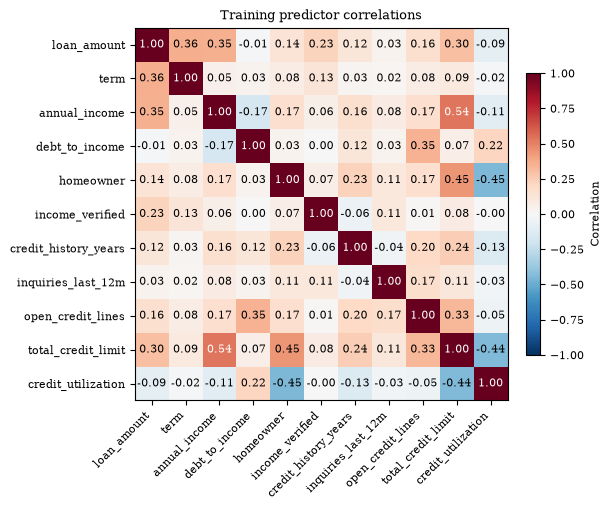

In [60]:
plot_correlations(X_train)

The heatmap shows positive correlations in red and negative correlations in blue;
white indicates a correlation close to zero. Each diagonal entry is 1 because a
predictor is perfectly correlated with itself.

The figure shows that there is moderate correlation between some of the predictors.
The highest correlation is between annual income and total credit limit, with a
training correlation of about 0.538. This correlation between predictor variables
suggests that PCA may be useful to reduce the dimensionality of the data and
capture the underlying structure.

<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Building the PCR pipeline

We next combine preprocessing, PCA, and regression in a single pipeline.

Build a
[`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
called `pipe_pcr` with these named steps:

1. `input_scale`:
   [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
2. `poly`:
   [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
   with `degree=2` and `include_bias=False`.
3. `scale`: another `StandardScaler()`.
4. `pca`:
   [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
   with `n_components=0.9` and `svd_solver='full'`.
5. `lr`:
   [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
   with `fit_intercept=True`.

Fit the pipeline on the training sample. Report the number of expanded features,
the number of retained components, and their total explained predictor variance.

*Hint:* Use `n_features_in_`, `n_components_`, and `explained_variance_ratio_`
from the fitted PCA step.

In [61]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# TODO: Build and fit pipe_pcr.

# TODO: Inspect the fitted PCA step and report its dimension and explained variance.

### Solution

The first scaler standardizes inputs before taking powers; the second standardizes
the expanded features before PCA. Keeping both scalers and PCA inside the pipeline
ensures that each CV fit learns these transformations from its training folds.

In [62]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Pipeline for PCR
pipe_pcr = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=0.9, svd_solver='full')),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

# Fit the pipeline to the training data
pipe_pcr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('input_scale', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['loan_amount','term','annual_income',...,'open_credit_lines', 'total_credit_limit','credit_utilization']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [63]:
# Store a reference to the fitted PCA step for inspection
initial_pca = pipe_pcr.named_steps['pca']

# Report the number of features and retained components
print(f'Expanded features: {initial_pca.n_features_in_}')
print(f'Retained components: {initial_pca.n_components_}')

# Report the proportion of variance retained by the PCA step
var_explained = initial_pca.explained_variance_ratio_.sum()
print(f'Predictor variance retained: {var_explained:.3f}')

Expanded features: 77
Retained components: 46
Predictor variance retained: 0.904


The expansion has 77 columns: eleven predictors, eleven squares, and 55 pairwise
interactions. PCA retains 46 components, explaining about 90.4% of predictor
variance. This percentage concerns the predictors, rather than interest rates.

<span style="display: none;">SolutionEnd</span>

***
## Part 3 — Selecting degree and retention

We now use cross-validation to choose the polynomial degree and the amount of
predictor variance retained by PCA.

Use
[`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
to select the optimal polynomial degree and PCA variance threshold jointly.

- Create a parameter grid with the following values:

    - Candidate degrees: `[1, 2, 3]`.
    - Candidate variance thresholds: `[0.7, 0.8, 0.9, 0.95, 0.99, 0.999, 0.9999]`.
- Use R² as the scoring metric, `scoring='r2'`.
- Define a CV splitter using
  [`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
  with 5 shuffled folds and a fixed seed of 1234.
- Create the `GridSearchCV` object with the argument `refit=True` so that the best model is refitted on the full training sample after the search.

Save the best model as `best_pcr` and call the provided `tabulate_cv_results(pcr_cv)` function to present the CV $R^2$
scores in a table with degrees as rows and variance thresholds as columns.

Use the table to discuss whether greater polynomial flexibility or more retained
variance always improves prediction.

In [64]:
def tabulate_cv_results(pcr_cv):
    """
    Tabulate the CV results from a GridSearchCV object for PCR with polynomial features.

    Parameters
    ----------
    pcr_cv : GridSearchCV
        Fitted GridSearchCV object

    Returns
    -------
    results : DataFrame
        Mean CV R² by polynomial degree and PCA variance threshold
    """
    keys = ['param_poly__degree', 'param_pca__n_components', 'mean_test_score']
    results = pd.DataFrame(pcr_cv.cv_results_)[keys]
    results = results.rename(
        columns={
            'mean_test_score': 'CV R²',
            'param_poly__degree': 'Poly degree',
            'param_pca__n_components': 'PCA variance',
        }
    )

    results = results.pivot(
        index='Poly degree', columns='PCA variance', values='CV R²'
    ).round(3)

    return results

In [65]:
from sklearn.model_selection import GridSearchCV, KFold

# Candidate polynomial degrees and PCA variance thresholds
degrees = [1, 2, 3]
thresholds = [0.7, 0.8, 0.9, 0.95, 0.99, 0.999, 0.9999]
# Scoring metric for GridSearchCV
scoring = 'r2'

# TODO: Define cv_splitter, the parameter grid, and pcr_cv.

# TODO: Fit the search and report the selected parameters and mean CV R².

# TODO: Save best_estimator_ as best_pcr.

### Solution

We compare 21 parameter combinations on the same five folds and select the
highest mean validation $R^2$.

In [66]:
from sklearn.model_selection import GridSearchCV, KFold

# Candidate polynomial degrees and PCA variance thresholds
degrees = [1, 2, 3]
thresholds = [0.7, 0.8, 0.9, 0.95, 0.99, 0.999, 0.9999]

# Scoring metric for GridSearchCV
scoring = 'r2'

# Define a cross-validation splitter with 5 shuffled folds and a fixed random state
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=1234)

We fit the grid search on the training sample:

In [67]:
# Create dictionary of parameters to search over for GridSearchCV
param_grid = {'poly__degree': degrees, 'pca__n_components': thresholds}

pcr_cv = GridSearchCV(
    pipe_pcr, param_grid, cv=cv_splitter, scoring=scoring, refit=True, n_jobs=4
)
pcr_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pca__n_components': [0.7, 0.8, ...], 'poly__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

We extract the refitted best model and report its parameters and CV score:

In [68]:
# Store the best estimator from the grid search
best_pcr = pcr_cv.best_estimator_

# Print the selected parameters and mean CV R²
print(pcr_cv.best_params_)
print(f'PCR CV selection R²: {pcr_cv.best_score_:.3f}')

{'pca__n_components': 0.999, 'poly__degree': 2}
PCR CV selection R²: 0.305


The search selects degree 2 and a variance threshold of 0.999, with mean CV
$R^2$ about 0.305. We tabulate all combinations below.

In [69]:
tabulate_cv_results(pcr_cv)

PCA variance,0.7000,0.8000,0.9000,0.9500,0.9900,0.9990,0.9999
Poly degree,,,,,,,
1,0.239,0.242,0.293,0.294,0.294,0.294,0.294
2,0.274,0.281,0.273,0.283,0.301,0.305,0.302
3,0.243,0.274,0.275,0.266,0.272,0.235,0.191


More flexibility or retained variance does not always improve prediction.
At degree 2, raising the variance threshold from 0.999 to 0.9999 lowers CV $R^2$
from about 0.305 to 0.302. Degree 3 reaches only about 0.275.

<span style="display: none;">SolutionEnd</span>

***
## Part 4 — Comparing prediction methods

We now compare PCR with polynomial regression without dimension reduction.
Does PCR improve predictions relative to using the polynomial features directly?

1. Build a new
   [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
   called `pipe_poly` with these named steps:

   1. `input_scale`:
      [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
   2. `poly`:
      [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
      with `degree=2` and `include_bias=False`,
   3. `scale`: another `StandardScaler()`, and
   4. `lr`:
      [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
      with `fit_intercept=True`.

2. Run a new
   [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
   search called `poly_cv` over degrees 1, 2, and 3, using
   the same training observations, `cv_splitter`, and `scoring`.

   Save the refitted best model as `best_poly`.

3. Use the provided `compare_cv_results(pcr_cv, poly_cv)` function to 
   compare the highest PCR CV $R^2$ across variance thresholds
   with the CV $R^2$ without PCA for each degree. Does discarding components help more at some
   degrees than at others?

   

Based on the validation results, which method would you choose for predicting interest rates?

In [70]:
def compare_cv_results(pcr_cv, poly_cv):
    """
    Compare validation scores with and without PCA at each polynomial degree.

    Parameters
    ----------
    pcr_cv : search
        Fitted PCR grid search
    poly_cv : search
        Fitted polynomial regression grid search

    Returns
    -------
    dataframe
        Best PCR and polynomial CV scores at each degree
    """
    df_pcr = pd.DataFrame(pcr_cv.cv_results_)
    pcr_scores = df_pcr.groupby('param_poly__degree')['mean_test_score'].max()

    df_poly = pd.DataFrame(poly_cv.cv_results_)
    poly_scores = df_poly.set_index('param_poly__degree')['mean_test_score']

    df_compare = pd.DataFrame({'PCR': pcr_scores, 'Without PCA': poly_scores})
    df_compare.index.name = 'Degree'
    return df_compare.round(3)

In [71]:
# TODO: Build pipe_poly

# TODO: Run GridSearchCV over degrees 1, 2, and 3.

# TODO: Save the best estimator as best_poly

# TODO: Call compare_cv_results(pcr_cv, poly_cv) and interpret the table.

### Solution

We use the same preprocessing, folds, and scorer, omitting the PCA step.

In [72]:
# Define pipeline for polynomial regression without PCA
pipe_poly = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

# Set up and fit GridSearchCV to search over polynomial degrees
poly_cv = GridSearchCV(
    pipe_poly, {'poly__degree': degrees}, cv=cv_splitter, scoring=scoring, refit=True
)
poly_cv.fit(X_train, y_train)

# Store the best estimator from the grid search
best_poly = poly_cv.best_estimator_

We can then use the provided function to compare the best CV $R^2$ for each degree with and without PCA:

In [73]:
# Tabulate the best CV scores for each polynomial degree
compare_cv_results(pcr_cv, poly_cv)

,PCR,Without PCA
Degree,,
1,0.294,0.294
2,0.305,0.302
3,0.275,-0.132


Both searches select degree 2. PCR has a slightly higher CV $R^2$: about 0.305
compared with 0.302 for polynomial regression. Based on this validation comparison, we would choose PCR for predicting interest rates.

At degree 3, PCA improves CV $R^2$ from about -0.132 to 0.275, highlighting the
benefit of discarding components when the polynomial expansion is large and
multicollinear.

<span style="display: none;">SolutionEnd</span>

***
## Part 5 — Evaluating unseen loans

We finish by evaluating both fitted models on unseen loans and plotting PCR's
predictions against observed rates.

1. Use `best_pcr` and `best_poly` to predict interest rates for the test set.
   Save the PCR predictions as `y_test_hat` and the polynomial predictions as
   `y_test_poly_hat`. Report the test $R^2$ for both models using
   [`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).
2. Use
   `scatter()`
   to plot observed test rates on the horizontal axis and PCR predictions on the
   vertical axis. Add a dashed line where predicted and observed rates are equal
   using
   `axline()`.
3. Briefly describe where the model overpredicts or underpredicts interest rates.

In [74]:
from sklearn.metrics import r2_score

# TODO: Predict with best_pcr and save the predictions as y_test_hat.

# TODO: Predict with best_poly and save the predictions as y_test_poly_hat.

# TODO: Compute and report the test R² for both models.

# TODO: Plot PCR predictions against observed test rates, with an equality line.

### Solution

Both grid searches have refitted their best models on the full training sample.
We now predict interest rates for the test sample.

In [75]:
from sklearn.metrics import r2_score

# Predict outcomes on the test set using the best PCR and polynomial models
y_test_hat = best_pcr.predict(X_test)
y_test_poly_hat = best_poly.predict(X_test)

# Compute the R² scores for both models on the test set
r2_test_pcr = r2_score(y_test, y_test_hat)
r2_test_poly = r2_score(y_test, y_test_poly_hat)

print(f'PCR test R²: {r2_test_pcr:.3f}')
print(f'Polynomial test R²: {r2_test_poly:.3f}')

PCR test R²: 0.284
Polynomial test R²: 0.288


The following code plots the PCR predictions against the observed loan interest rates on the test sample. The dashed line indicates where predicted and observed rates are equal.

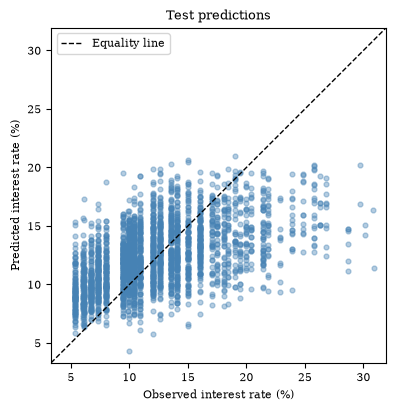

In [76]:
plt.figure(figsize=(4.5, 4), layout='constrained')
# Scatter plot of observed vs predicted interest rates
plt.scatter(y_test, y_test_hat, s=12, alpha=0.4, c='steelblue')
# plot 45-degree equality line
plt.axline((0, 0), slope=1, c='black', ls='--', lw=1, label='Equality line')
plt.gca().set_aspect('equal', adjustable='box')
# Use common limits that include all observed and predicted rates
rate_min = min(y_test.min(), y_test_hat.min()) - 1
rate_max = max(y_test.max(), y_test_hat.max()) + 1
plt.xlim((rate_min, rate_max))
plt.ylim((rate_min, rate_max))
plt.xlabel('Observed interest rate (%)')
plt.ylabel('Predicted interest rate (%)')
plt.legend()
_ = plt.title('Test predictions')

Test $R^2$ is about 0.284 for PCR and 0.288 for polynomial regression, reversing
their small CV difference. This small reversal suggests that the two methods
perform similarly, with their ranking depending on the evaluation sample.

The PCR predictions cover a narrower range than observed rates: the model
underpredicts many high-rate loans and overpredicts some low-rate loans.

<span style="display: none;">SolutionEnd</span>